In [31]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import os

from src.data_loader import *
from src.models import *
from src.trainer import *

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Carregamento dos dados:

In [32]:
root = "pa3_dados"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Rodando em: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

label_to_idx, idx_to_label, class_names = get_class_mappings(root)
print(f"Total de classes carregadas: {len(class_names)}")

Rodando em: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
Total de classes carregadas: 21


# Parte 0 — O piso:

### 0.0: Carregamento dos dados de treino (Supervisionados)

In [33]:
root = "pa3_dados"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Rodando em: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

label_to_idx, idx_to_label, class_names = get_class_mappings(root)
print(f"Total de classes carregadas: {len(class_names)}")

Rodando em: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
Total de classes carregadas: 21


### 0.1: Treinem um classificador supervisionado só com rotulos_5.csv (105 imagens), em duas versões: 

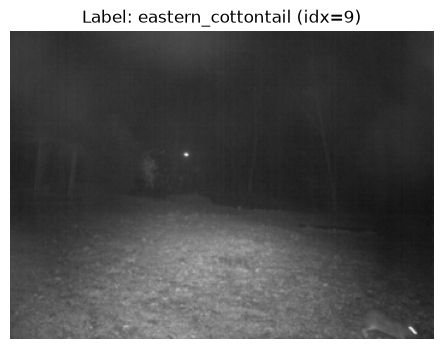

In [34]:
# Carrega o orçamento padrão de 5 rótulos por classe (105 imagens no treino)
train_loader_5, val_loader, test_loader = get_supervised_dataloaders(
    root_dir=root,
    labels_qtt=5,
    batch_size=16,
    img_size=(256, 352),
    num_workers=2,
    seed=42
)

# Visualizando uma amostra do train_loader_5 (revertendo a normalização do ImageNet para exibir as cores)
images, labels = next(iter(train_loader_5))
img_sample = images[0].permute(1, 2, 0).numpy()
img_sample = np.clip(img_sample * IMAGENET_STD + IMAGENET_MEAN, 0, 1)

plt.figure(figsize=(6, 4))
plt.imshow(img_sample)
plt.title(f"Label: {idx_to_label[labels[0].item()]} (idx={labels[0].item()})")
plt.axis("off")
plt.show()

#### (a) uma CNN pequena treinada do zero; 

In [35]:
cnn_zero = build_model("small_cnn", num_classes=21).to(device)
print(f"Treinando SmallCNN do zero ({count_parameters(cnn_zero):,} parâmetros)...")

cnn_zero, hist_cnn = train_model(
    model=cnn_zero,
    train_loader=train_loader_5,
    val_loader=val_loader,
    device=device,
    model_type="small_cnn",
    epochs=50,
    lr_head=1e-3,
    weight_decay=1e-2,
    save_path="checkpoints/piso_small_cnn_b5_s42.pt",
    seed=42
)

Treinando SmallCNN do zero (394,293 parâmetros)...
Época [01/50] Train Loss: 3.1481 | Train F1: 0.038 || Val Loss: 3.0388 | Val F1: 0.015 (Acc: 0.054) [Novo Melhor Val F1]
Época [02/50] Train Loss: 2.8068 | Train F1: 0.150 || Val Loss: 3.0387 | Val F1: 0.017 (Acc: 0.059) [Novo Melhor Val F1]
Época [03/50] Train Loss: 2.7551 | Train F1: 0.104 || Val Loss: 3.0304 | Val F1: 0.046 (Acc: 0.079) [Novo Melhor Val F1]
Época [04/50] Train Loss: 2.6008 | Train F1: 0.163 || Val Loss: 2.9426 | Val F1: 0.086 (Acc: 0.134) [Novo Melhor Val F1]
Época [05/50] Train Loss: 2.6082 | Train F1: 0.130 || Val Loss: 2.8976 | Val F1: 0.098 (Acc: 0.144) [Novo Melhor Val F1]
Época [06/50] Train Loss: 2.5014 | Train F1: 0.154 || Val Loss: 2.8378 | Val F1: 0.142 (Acc: 0.183) [Novo Melhor Val F1]
Época [10/50] Train Loss: 2.3860 | Train F1: 0.235 || Val Loss: 2.8498 | Val F1: 0.128 (Acc: 0.153)
Época [15/50] Train Loss: 2.2978 | Train F1: 0.215 || Val Loss: 2.9683 | Val F1: 0.107 (Acc: 0.139)
Época [19/50] Train Los

#### (b) o backbone que vocês vão usar no resto do PA, partindo do ImageNet, com fine-tuning.

In [36]:
resnet_piso = build_model("resnet18", num_classes=21, pretrained=True).to(device)
print(f"Treinando ResNet-18 ImageNet ({count_parameters(resnet_piso):,} parâmetros)...")

resnet_piso, hist_resnet = train_model(
    model=resnet_piso,
    train_loader=train_loader_5,
    val_loader=val_loader,
    device=device,
    model_type="resnet18",
    epochs=40,
    lr_backbone=1e-4,
    lr_head=1e-3,
    weight_decay=1e-2,
    save_path="checkpoints/piso_resnet18_b5_s42.pt",
    seed=42
)

Treinando ResNet-18 ImageNet (11,187,285 parâmetros)...
Época [01/40] Train Loss: 3.2422 | Train F1: 0.054 || Val Loss: 2.8372 | Val F1: 0.130 (Acc: 0.168) [Novo Melhor Val F1]
Época [02/40] Train Loss: 2.0864 | Train F1: 0.547 || Val Loss: 2.4941 | Val F1: 0.263 (Acc: 0.282) [Novo Melhor Val F1]
Época [03/40] Train Loss: 1.4582 | Train F1: 0.712 || Val Loss: 2.2498 | Val F1: 0.273 (Acc: 0.282) [Novo Melhor Val F1]
Época [04/40] Train Loss: 1.0104 | Train F1: 0.901 || Val Loss: 2.1591 | Val F1: 0.296 (Acc: 0.282) [Novo Melhor Val F1]
Época [05/40] Train Loss: 0.7826 | Train F1: 0.896 || Val Loss: 2.1504 | Val F1: 0.355 (Acc: 0.356) [Novo Melhor Val F1]
Época [06/40] Train Loss: 0.5453 | Train F1: 0.934 || Val Loss: 2.1165 | Val F1: 0.366 (Acc: 0.361) [Novo Melhor Val F1]
Época [08/40] Train Loss: 0.3073 | Train F1: 0.990 || Val Loss: 2.0738 | Val F1: 0.378 (Acc: 0.366) [Novo Melhor Val F1]
Época [10/40] Train Loss: 0.1883 | Train F1: 0.981 || Val Loss: 2.1083 | Val F1: 0.351 (Acc: 0.32

### 0.2: Avaliação no `test_public` (F1 Macro e Acurácia) e Matriz de Confusão da versão (b)

Comparativo da Parte 0 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Val F1 Macro (Melhor),Test F1 Macro,Test Acurácia
0,0.1 (a) SmallCNN (do zero),394293,0.2341,0.2100,0.2306
1,0.1 (b) ResNet-18 (ImageNet Fine-Tuning),11187285,0.3816,0.4559,0.4723


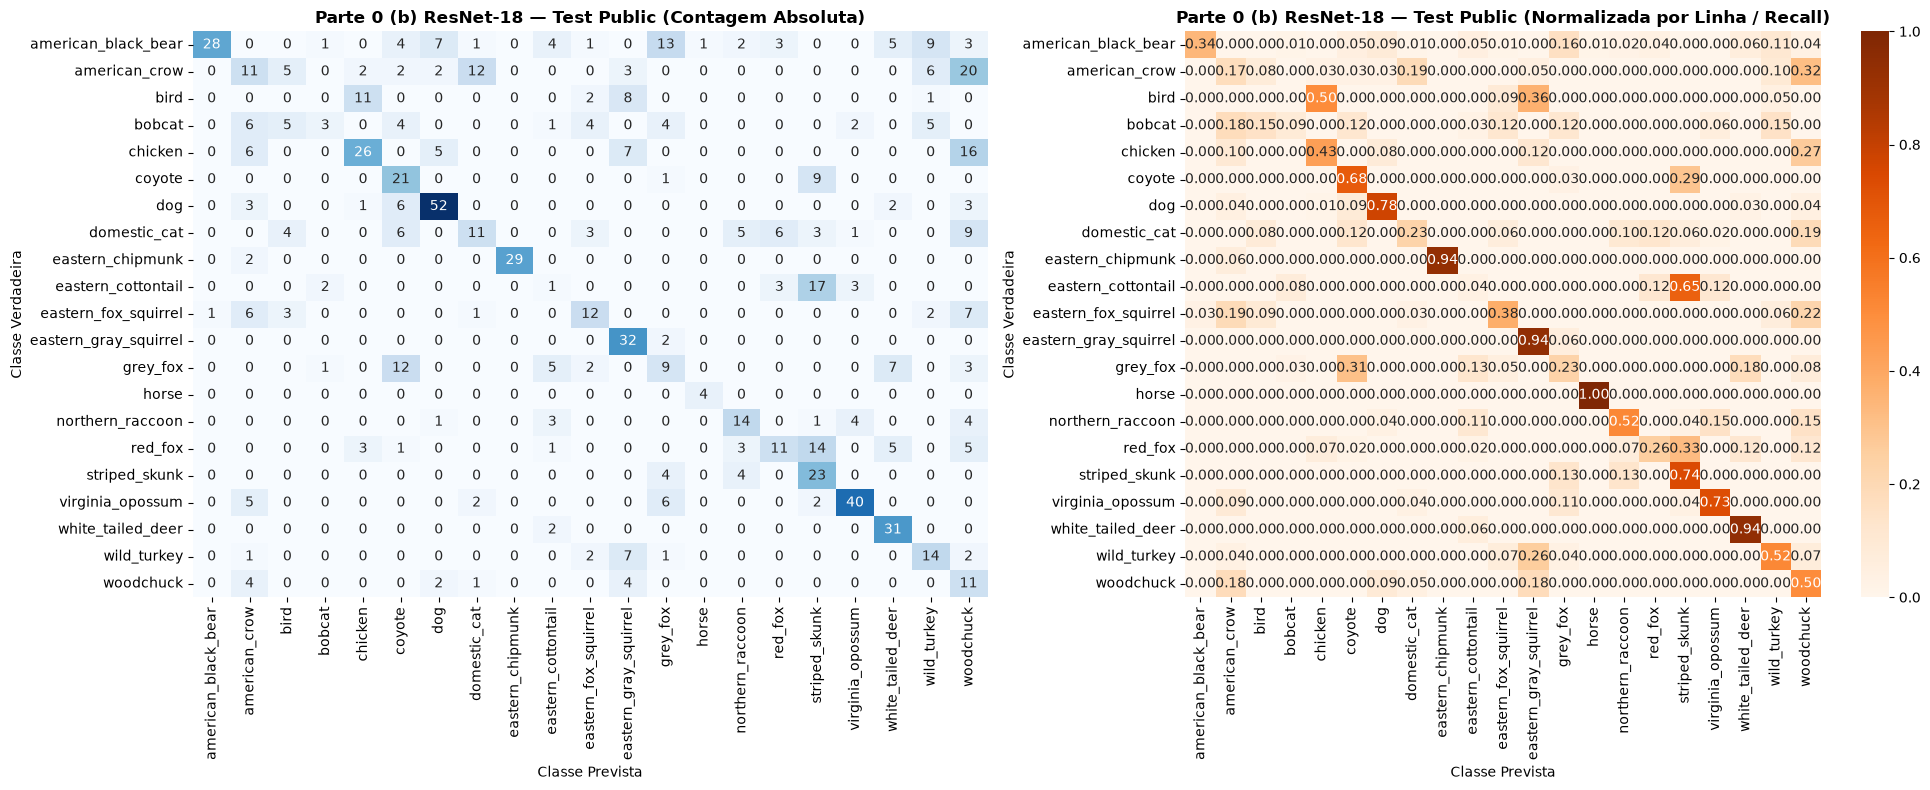

In [37]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints de (a) e (b) no test_public
test_metrics_cnn = evaluate(cnn_zero, test_loader, criterion, device)
test_metrics_res = evaluate(resnet_piso, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "0.1 (a) SmallCNN (do zero)",
        "Parâmetros": count_parameters(cnn_zero),
        "Val F1 Macro (Melhor)": round(hist_cnn["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_cnn["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_cnn["acc"], 4),
    },
    {
        "Modelo": "0.1 (b) ResNet-18 (ImageNet Fine-Tuning)",
        "Parâmetros": count_parameters(resnet_piso),
        "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_res["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_res["acc"], 4),
    }
])
print("Comparativo da Parte 0 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

# Salva o resultado oficial do piso (b) no curva_orcamento.csv
df_orc = log_budget_result(
    csv_path="curva_orcamento.csv",
    metodo="piso",
    orcamento=5,
    seed=42,
    f1_macro=test_metrics_res["f1_macro"],
    acuracia=test_metrics_res["acc"]
)

# Plota a Matriz de Confusão da versão (b) no test_public
plot_confusion_matrix(
    y_true=test_metrics_res["y_true"],
    y_pred=test_metrics_res["y_pred"],
    class_names=class_names,
    title="Parte 0 (b) ResNet-18 — Test Public",
    save_fig="figures/parte0_matriz_confusao_resnet18.png"
)

### 0.3: Curva de treino e validação da versão (b) — Em que época ela começa a decorar?

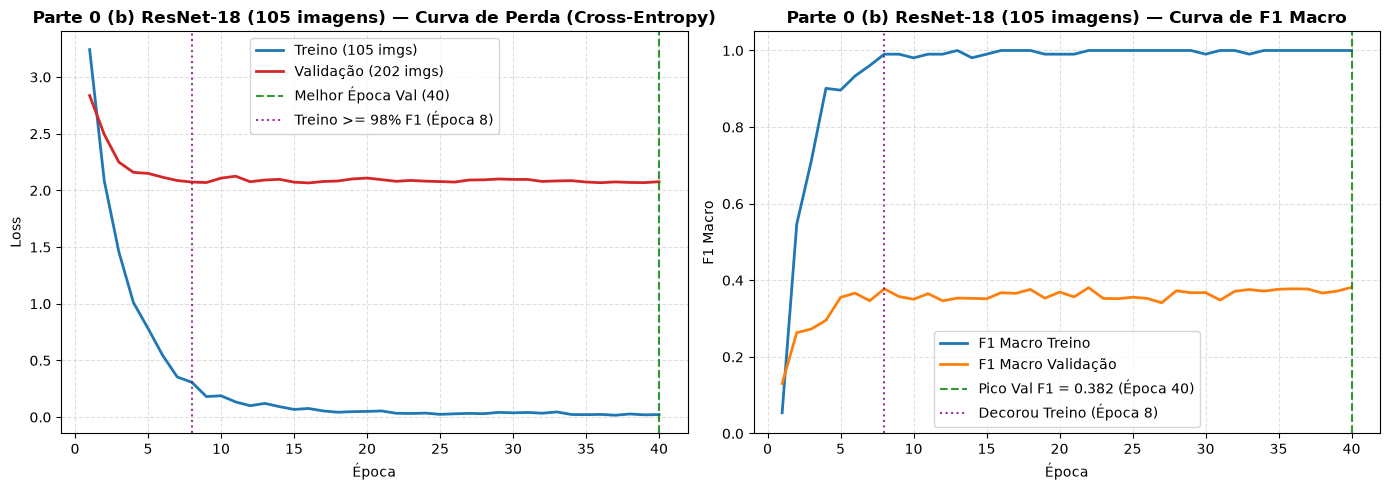

Época em que o treino atingiu >= 98% de F1 Macro: Época 8
Época de pico do F1 Macro na validação:  Época 40


In [38]:
plot_learning_curves(
    hist_resnet,
    title_prefix="Parte 0 (b) ResNet-18 (105 imagens)",
    save_fig="figures/parte0_curvas_resnet18.png"
)

# Diagnóstico numérico automático para responder à pergunta 0.3:
mem_rows = hist_resnet[hist_resnet["train_f1_macro"] >= 0.98]
ep_decorou = int(mem_rows.iloc[0]["epoch"]) if len(mem_rows) > 0 else "N/A"
ep_melhor_val = hist_resnet.attrs["best_epoch"]

print(f"Época em que o treino atingiu >= 98% de F1 Macro: Época {ep_decorou}")
print(f"Época de pico do F1 Macro na validação:  Época {ep_melhor_val}")

# Parte 1 — Usando o que não tem rótulo (Trilha A — Auto-supervisionado):

### 1.0: Carregamento dos dados de treino (Não-Supervisionados)

In [39]:
root = "pa3_dados"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Rodando em: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

label_to_idx, idx_to_label, class_names = get_class_mappings(root)
print(f"Total de classes carregadas: {len(class_names)}")

Rodando em: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)
Total de classes carregadas: 21


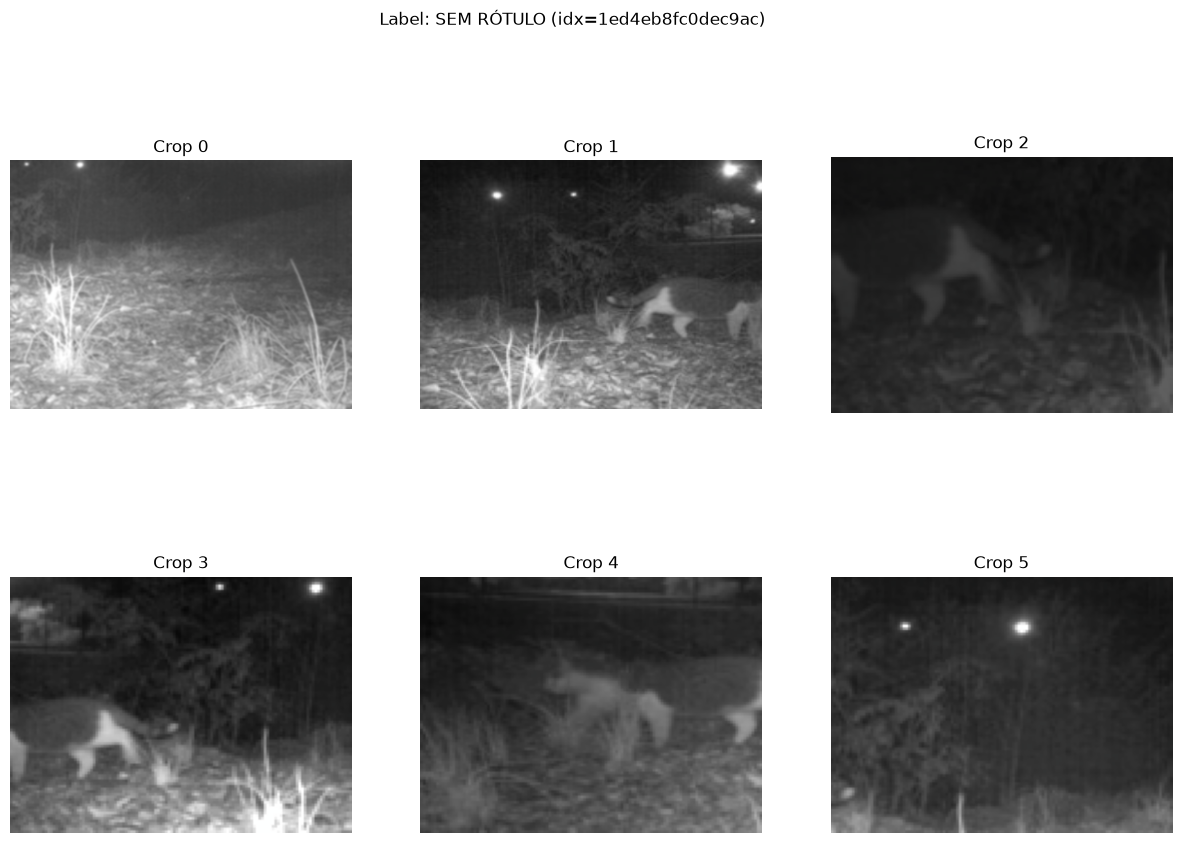

In [40]:
# Baseline: Agressivo e com Multi-Crop (O padrão que deve falhar no ENA24)
swav_transforms_baseline_ena24 = MultiCropDataAugmentation(
    size_crops=[(256, 352), (96, 128)], # Globais e Locais (resolução menor)
    num_crops=[2, 4],                   # 2 visões globais, 4 visões locais
    min_scale=[0.14, 0.05],             # Escalas originais do paper
    max_scale=[1.0, 0.14]
)

# Carrega os dados nao supervisionados
train_loader_unsup_baseline, val_loader_unsup_baseline, test_loader_unsup_baseline = get_unsupervised_dataloaders(
    root_dir=root,
    batch_size=16,
    img_size=(256, 352),
    num_workers=2,
    seed=42,
    transform=swav_transforms_baseline_ena24
)

# Visualizando uma amostra do train_loader_unsup_baseline (revertendo a normalização do ImageNet para exibir as cores)
images, labels = next(iter(train_loader_unsup_baseline))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = np.ravel(axes)
for i in range(6):
    img_sample = images[i][0].permute(1, 2, 0).numpy()
    img_sample = np.clip(img_sample * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
    axes[i].imshow(img_sample)
    axes[i].set(title=f"Crop {i}")
    axes[i].axis("off")
    
fig.suptitle(f"Label: {idx_to_label.get(labels[0], "SEM RÓTULO")} (idx={labels[0]})")
plt.show()

In [41]:
# Instancia a baseline pura (para guardar)
imagenet_puro = build_resnet18(pretrained=True)

# Cria um modelo independente na memória para o SwAV modificar
resnet_piso_para_swav = build_resnet18(pretrained=True)

# Instancia aleatoria
imagenet_aleatorio = build_resnet18(pretrained=False)

### 1.1: Continuem o pré-treino do backbone ImageNet com SimCLR ou SwAV sobre as 6.505 imagens do train.  

In [42]:
# Cada época leva alguns minutos; aumente para resultados melhores (ex.: 100+)
EPOCHS = 10

# 1. Instanciar o modelo unificado
swav_model_imagenet_piso = SwAVModel(
    in_features=512, 
    prototype_dim=300,
    backbone=resnet_piso_para_swav
).to(device)

# 2. Configurar o otimizador com os parâmetros do modelo unificado
# separando os parametros do backbone do demais (esses ja foram aprendidos)
backbone_params = swav_model_imagenet_piso.backbone.parameters()
head_params = [
    *list(swav_model_imagenet_piso.projection_head.parameters()),
    *list(swav_model_imagenet_piso.prototype.parameters())
]

optimizer = torch.optim.Adam(
    [
        {'params': backbone_params, 'lr': 1e-5},  # LR 100x MENOR para proteger o ImageNet
        {'params': head_params, 'lr': 1e-3}       # LR normal para treinar a cabeça aleatória
    ], 
    weight_decay=1e-6
)

# 3. Chamar a função de treinamento principal
epoch_wise_loss, trained_swav_model_imagenet_piso = train_swav(
    swav_model_imagenet_piso,
    train_loader_unsup_baseline, # O DataLoader não muda
    optimizer,
    crops_for_assign=[0, 1], # códigos calculados a partir dos crops de alta resolução [os dois primeiros]
    temperature=0.1,
    epochs=EPOCHS,
    device=device
)

# 4. Salvar os pesos do backbone para o fine-tuning
#    Você pode extrair o state_dict apenas da parte do backbone do modelo treinado
feature_backbone_weights = trained_swav_model_imagenet_piso.backbone.state_dict()

Epoch 1/10: 100%|██████████| 407/407 [01:06<00:00,  6.13it/s, loss=4.857]


Epoch: 1 | Loss: 5.141


Epoch 2/10: 100%|██████████| 407/407 [01:05<00:00,  6.23it/s, loss=5.503]


Epoch: 2 | Loss: 4.841


Epoch 3/10: 100%|██████████| 407/407 [01:05<00:00,  6.21it/s, loss=4.834]


Epoch: 3 | Loss: 4.717


... (10 outputs left out)

Epoch 9/10: 100%|██████████| 407/407 [01:06<00:00,  6.13it/s, loss=4.248]


Epoch: 9 | Loss: 4.487


Epoch 10/10: 100%|██████████| 407/407 [01:05<00:00,  6.21it/s, loss=4.674]


Epoch: 10 | Loss: 4.465


### 1.2: Depois façam avaliação linear e fine-tuning com os 105 rótulos.

##### Obrigatório: avaliação linear com três backbones lado a lado: 
- ImageNet puro;
- ImageNet + auto-supervisionado;
- Aleatório + auto-supervisionado.  

O pré-treino no domínio vale alguma coisa em cima do ImageNet?

In [43]:
# 1. Instanciar o modelo unificado
swav_model_imagenet_aleatorio = SwAVModel(
    in_features=512, 
    prototype_dim=300,
    backbone=imagenet_aleatorio
).to(device)

# 2. Configurar o otimizador com os parâmetros do modelo unificado
# separando os parametros do backbone do demais (esses ja foram aprendidos)
backbone_params = swav_model_imagenet_aleatorio.backbone.parameters()
head_params = [
    *list(swav_model_imagenet_aleatorio.projection_head.parameters()),
    *list(swav_model_imagenet_aleatorio.prototype.parameters())
]

optimizer = torch.optim.Adam(
    [
        # MUDEI O LR PARA 1e-3
        {'params': backbone_params, 'lr': 1e-3},  # LR 100x MENOR para proteger o ImageNet
        {'params': head_params, 'lr': 1e-3}       # LR normal para treinar a cabeça aleatória
    ], 
    weight_decay=1e-6
)


# 3. Chamar a função de treinamento principal
epoch_wise_loss, trained_swav_model_imagenet_aleatorio = train_swav(
    swav_model_imagenet_aleatorio,
    train_loader_unsup_baseline, # O DataLoader não muda
    optimizer,
    crops_for_assign=[0, 1], # códigos calculados a partir dos crops de alta resolução [os dois primeiros]
    temperature=0.1,
    epochs=EPOCHS,
    device=device
)

# 4. Salvar os pesos do backbone para o fine-tuning
#    Você pode extrair o state_dict apenas da parte do backbone do modelo treinado
feature_backbone_weights = trained_swav_model_imagenet_aleatorio.backbone.state_dict()

Epoch 1/10: 100%|██████████| 407/407 [01:06<00:00,  6.16it/s, loss=5.534]


Epoch: 1 | Loss: 5.618


Epoch 2/10: 100%|██████████| 407/407 [01:07<00:00,  6.05it/s, loss=5.527]


Epoch: 2 | Loss: 5.539


Epoch 3/10: 100%|██████████| 407/407 [01:05<00:00,  6.19it/s, loss=5.419]


Epoch: 3 | Loss: 5.477


... (10 outputs left out)

Epoch 9/10: 100%|██████████| 407/407 [01:06<00:00,  6.09it/s, loss=5.228]


Epoch: 9 | Loss: 5.370


Epoch 10/10: 100%|██████████| 407/407 [01:08<00:00,  5.96it/s, loss=5.309]

Epoch: 10 | Loss: 5.362


In [44]:
# 1. Preparando o backbone da ImageNet pura (removido a 'fc')
backbone_imagenet_puro = nn.Sequential(*list(imagenet_puro.children())[:-1])

# 2. Extraindo os backbones que foram treinados no SwAV
# (Eles já estão no formato certo dentro da classe SwAVModel)
backbone_swav_piso      = trained_swav_model_imagenet_piso.backbone
backbone_swav_aleatorio = trained_swav_model_imagenet_aleatorio.backbone

# 3. Criando os 3 classificadores
probe_baseline       = LinearProbe(backbone=backbone_imagenet_puro, num_classes=21)
probe_swav_imgnet    = LinearProbe(backbone=backbone_swav_piso, num_classes=21)
probe_swav_aleatorio = LinearProbe(backbone=backbone_swav_aleatorio, num_classes=21)

print("Iniciando Avaliação Linear...")

# Rodando para a ImageNet Pura (O Piso)
f1_base, acc_base = train_linear_probe(probe_baseline, train_loader_5, val_loader, device=device)
print(f"[ImageNet Puro] F1-Macro: {f1_base:.4f} | Acurácia: {acc_base:.4f}")

# Rodando para o SwAV a partir da ImageNet
f1_swav, acc_swav = train_linear_probe(probe_swav_imgnet, train_loader_5, val_loader, device=device)
print(f"[SwAV + ImageNet] F1-Macro: {f1_swav:.4f} | Acurácia: {acc_swav:.4f}")

# Rodando para o SwAV a partir do Zero (Aleatório)
f1_rnd, acc_rnd = train_linear_probe(probe_swav_aleatorio, train_loader_5, val_loader, device=device)
print(f"[SwAV + Aleatório] F1-Macro: {f1_rnd:.4f} | Acurácia: {acc_rnd:.4f}")

Iniciando Avaliação Linear...
[ImageNet Puro] F1-Macro: 0.3611 | Acurácia: 0.3663
[SwAV + ImageNet] F1-Macro: 0.3547 | Acurácia: 0.3614
[SwAV + Aleatório] F1-Macro: 0.1656 | Acurácia: 0.1931


In [45]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints no test_public
test_metrics_baseline       = evaluate(probe_baseline, test_loader, criterion, device)
test_metrics_swav_imgnet    = evaluate(probe_swav_imgnet, test_loader, criterion, device)
test_metrics_swav_aleatorio = evaluate(probe_swav_aleatorio, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "ImageNet",
        "Parâmetros": count_parameters(probe_baseline),
        # "Val F1 Macro (Melhor)": round(hist_cnn["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_baseline["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_baseline["acc"], 4),
    },
    {
        "Modelo": "ImageNet Fine-Tuning + AutoSupervisionado",
        "Parâmetros": count_parameters(probe_swav_imgnet),
        # "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_swav_imgnet["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_swav_imgnet["acc"], 4),
    },
    {
        "Modelo": "ImageNet Aleatório + AutoSupervisionado",
        "Parâmetros": count_parameters(probe_swav_aleatorio),
        # "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_swav_aleatorio["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_swav_aleatorio["acc"], 4),
    }
])
print("Comparativo da Parte 1 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

# # Salva o resultado oficial do piso (b) no curva_orcamento.csv
# df_orc = log_budget_result(
#     csv_path="curva_orcamento.csv",
#     metodo="piso",
#     orcamento=5,
#     seed=42,
#     f1_macro=test_metrics_res["f1_macro"],
#     acuracia=test_metrics_res["acc"]
# )

# # Plota a Matriz de Confusão da versão (b) no test_public
# plot_confusion_matrix(
#     y_true=test_metrics_res["y_true"],
#     y_pred=test_metrics_res["y_pred"],
#     class_names=class_names,
#     title="Parte 0 (b) ResNet-18 — Test Public",
#     save_fig="figures/parte0_matriz_confusao_resnet18.png"
# )

Comparativo da Parte 1 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Test F1 Macro,Test Acurácia
0,ImageNet,11187285,0.5138,0.5438
1,ImageNet Fine-Tuning + AutoSupervisionado,11187285,0.3801,0.4328
2,ImageNet Aleatório + AutoSupervisionado,11187285,0.1038,0.1344


In [46]:
# 1. Recupera o backbone treinado pelo SwAV (ou ImageNet puro)
# Deepcopy para garantir que o fine-tuning não afete outras avaliações
backbone_swav_para_ft = copy.deepcopy(trained_swav_model_imagenet_piso.backbone)

# 2. Instancia o modelo de fine-tuning
modelo_ft = FineTunedModel(backbone=backbone_swav_para_ft, num_classes=21, dropout_p=0.3)

# 3. Treina usando os dados supervisionados (105 imagens)
modelo_ft_treinado, f1_final, acc_final = train_fine_tuning(
    modelo_ft, 
    train_loader_5,
    val_loader,
    epochs=40,
    device=device
)

Nova melhor F1 Macro: 0.1386 na época 1 | Val Acc: 0.2129
Nova melhor F1 Macro: 0.2138 na época 2 | Val Acc: 0.3020
Nova melhor F1 Macro: 0.2438 na época 4 | Val Acc: 0.3069
Nova melhor F1 Macro: 0.2765 na época 5 | Val Acc: 0.3267
Nova melhor F1 Macro: 0.3139 na época 8 | Val Acc: 0.3416
Nova melhor F1 Macro: 0.3146 na época 9 | Val Acc: 0.3317
Nova melhor F1 Macro: 0.3293 na época 10 | Val Acc: 0.3762
Época 10/40 | Loss Treino: 1.3146 | Val F1: 0.3293 | Val Acc: 0.3762
Nova melhor F1 Macro: 0.3342 na época 15 | Val Acc: 0.3564
Nova melhor F1 Macro: 0.3504 na época 16 | Val Acc: 0.3663
Época 20/40 | Loss Treino: 0.7829 | Val F1: 0.3200 | Val Acc: 0.3515
Nova melhor F1 Macro: 0.3818 na época 21 | Val Acc: 0.3960
Nova melhor F1 Macro: 0.3845 na época 26 | Val Acc: 0.3960
Nova melhor F1 Macro: 0.3887 na época 28 | Val Acc: 0.3960
Nova melhor F1 Macro: 0.4081 na época 29 | Val Acc: 0.4158
Época 30/40 | Loss Treino: 0.5133 | Val F1: 0.3932 | Val Acc: 0.4010
Época 40/40 | Loss Treino: 0.477

In [47]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints no test_public
test_metrics_swav_imgnet_tuned = evaluate(modelo_ft_treinado, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "ImageNet Fine-Tuning + AutoSupervisionado",
        "Parâmetros": count_parameters(modelo_ft_treinado),
        # "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_swav_imgnet_tuned["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_swav_imgnet_tuned["acc"], 4),
    },
])
print("Comparativo da Parte 1 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

Comparativo da Parte 1 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Test F1 Macro,Test Acurácia
0,ImageNet Fine-Tuning + AutoSupervisionado,11187285,0.3841,0.434


Inserimos o Imagenet com pré-treino como backbone do SwAV, setando os learning rates para:  
- `lr=10^{-3}` para os parâmetros do backbone;
- `lr=10^{-5}` para os demais parâmetros da SwAV.
Fizemos isso pois os demais parâmetros começam aleatórios, então seus gradientes iriam levar o parâmetros já treinados para longe de seus "mínimos locais" já aprendidos.

Apesar de o Imagenet já treinado com os 105 exemplos ter sido muito superior ao modelo com os pesos do Imagenet iniciados aleatoriamente, as suas métricas no treino, com 10 épocas, não chegaram a superar o Imagenet default, embora tenham se aproximado.  

Avaliando ainda as métricas no conjunto de teste público, os resultados foram ainda mais favoráveis ao Imagenet puro, que conseguiu aumentar em muito a sua margem.  

Após o fine-tuning, seguindo a mesma parametrização do learning rate, porém com mais épocas, o modelo melhorou em relação a versão anterior, mas conseguiu apenas reduzir a diferença para o Imagenet padrão.  

Como hipóteses, temos a de que o learning rate do backbone ainda está muito grande, distanciando das melhores regiões no início do treino. Além disso, a quantidade de épocas pode ter sido insuficiente (limitada pelo tempo de processamento disponível). Como próximos passos, ficam registradas três intenções de teste:
- Diminuir o learning rate do backbone, tanto antes quanto durante o fine-tuning;
- Aumentar a quantidade de épocas;
- Paralizar a atualização dos pesos do backbone (pré e durante fine-tuning) no início do treino, permitindo que a rede aprenda os padrões das camadas posteriores e, só então, passe a tentar melhorar o backbone também, impedindo que a aleatoridedade destrua o conhecimento já aprendido.

##### Obrigatório: um experimento sobre aumentação. 
Um random resized crop numa imagem em que o animal ocupa 2% do quadro gera, na maioria das vezes, um par positivo sem animal nenhum. O que a rede aprende a aproximar nesse caso?  
Escolham uma mudança na aumentação, meçam e expliquem.

In [48]:
# Instancia a baseline pura (para guardar)
imagenet_puro_v2 = build_resnet18(pretrained=True)

# Cria uma cópia independente na memória para o SwAV modificar
resnet_piso_para_swav_v2 = build_resnet18(pretrained=True)

# Instancia aleatoria
imagenet_aleatorio_v2 = build_resnet18(pretrained=False)

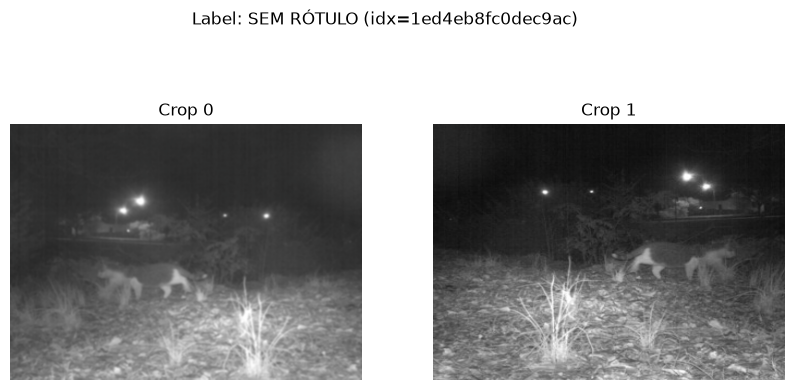

In [49]:
# swav_transforms_ena24 = MultiCropDataAugmentation(
#     size_crops=[(256, 352), (96, 128)], # Globais e Locais (resolução menor)
#     num_crops=[2, 4],                   # 2 visões globais, 4 visões locais
#     min_scale=[0.14, 0.05],             # Escalas originais do paper
#     max_scale=[1.0, 0.14]
# )
swav_transforms_ena24 = MultiCropDataAugmentation(
    size_crops=[(256, 352)],   # Usa a resolução retangular do seu dataset
    num_crops=[2],             # Gera apenas 2 visões globais (sem os crops locais minúsculos)
    min_scale=[0.5],
    max_scale=[1.0]
)

# Carrega os dados nao supervisionados
train_loader_unsup, val_loader_unsup, test_loader_unsup = get_unsupervised_dataloaders(
    root_dir=root,
    batch_size=16,
    img_size=(256, 352),
    num_workers=2,
    seed=42,
    transform=swav_transforms_ena24
)

# Visualizando uma amostra do train_loader_unsup (revertendo a normalização do ImageNet para exibir as cores)
images, labels = next(iter(train_loader_unsup))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes = np.ravel(axes)
for i in range(2):
    img_sample = images[i][0].permute(1, 2, 0).numpy()
    img_sample = np.clip(img_sample * IMAGENET_STD + IMAGENET_MEAN, 0, 1)
    axes[i].imshow(img_sample)
    axes[i].set(title=f"Crop {i}")
    axes[i].axis("off")
    
fig.suptitle(f"Label: {idx_to_label.get(labels[0], "SEM RÓTULO")} (idx={labels[0]})")
plt.show()

In [50]:
# Cada época leva alguns minutos; aumente para resultados melhores (ex.: 100+)
EPOCHS = 10

# 1. Instanciar o modelo unificado
swav_model_imagenet_piso_v2 = SwAVModel(
    in_features=512, 
    prototype_dim=300,
    backbone=resnet_piso_para_swav_v2
).to(device)

# 2. Configurar o otimizador com os parâmetros do modelo unificado
# separando os parametros do backbone do demais (esses ja foram aprendidos)
backbone_params = swav_model_imagenet_piso_v2.backbone.parameters()
head_params = [
    *list(swav_model_imagenet_piso_v2.projection_head.parameters()),
    *list(swav_model_imagenet_piso_v2.prototype.parameters())
]

optimizer = torch.optim.Adam(
    [
        # MUDEI O LR PARA 1e-5
        {'params': backbone_params, 'lr': 1e-5},  # LR 100x MENOR para proteger o ImageNet
        {'params': head_params, 'lr': 1e-3}       # LR normal para treinar a cabeça aleatória
    ], 
    weight_decay=1e-6
)

# 3. Chamar a função de treinamento principal
epoch_wise_loss, trained_swav_model_imagenet_piso_v2 = train_swav(
    swav_model_imagenet_piso_v2,
    train_loader_unsup, # O DataLoader não muda
    optimizer,
    crops_for_assign=[0, 1], # códigos calculados a partir dos crops de alta resolução [os dois primeiros]
    temperature=0.1,
    epochs=EPOCHS,
    device=device
)

# 4. Salvar os pesos do backbone para o fine-tuning
#    Você pode extrair o state_dict apenas da parte do backbone do modelo treinado
feature_backbone_weights = trained_swav_model_imagenet_piso_v2.backbone.state_dict()

Epoch 1/10: 100%|██████████| 407/407 [00:53<00:00,  7.67it/s, loss=4.140]


Epoch: 1 | Loss: 4.521


Epoch 2/10: 100%|██████████| 407/407 [00:54<00:00,  7.51it/s, loss=4.428]


Epoch: 2 | Loss: 4.210


Epoch 3/10: 100%|██████████| 407/407 [00:52<00:00,  7.73it/s, loss=4.385]


Epoch: 3 | Loss: 4.117


... (10 outputs left out)

Epoch 9/10: 100%|██████████| 407/407 [00:49<00:00,  8.16it/s, loss=4.040]


Epoch: 9 | Loss: 3.867


Epoch 10/10: 100%|██████████| 407/407 [00:50<00:00,  8.12it/s, loss=4.138]

Epoch: 10 | Loss: 3.847


In [51]:
# 1. Extraindo o backbone que treinado no SwAV
backbone_swav_piso_v2 = trained_swav_model_imagenet_piso_v2.backbone

# 2. Criando o classificador
probe_swav_imgnet_v2 = LinearProbe(backbone=backbone_swav_piso_v2, num_classes=21)

print("Iniciando Avaliação Linear...")

# Rodando para o SwAV a partir da ImageNet
f1_swav, acc_swav = train_linear_probe(probe_swav_imgnet_v2, train_loader_5, val_loader, device=device)
print(f"[SwAV + ImageNet] F1-Macro: {f1_swav:.4f} | Acurácia: {acc_swav:.4f}")

Iniciando Avaliação Linear...
[SwAV + ImageNet] F1-Macro: 0.3302 | Acurácia: 0.3416


In [52]:
criterion = nn.CrossEntropyLoss()

# Avalia os melhores checkpoints no test_public
test_metrics_swav_imgnet_v2 = evaluate(probe_swav_imgnet_v2, test_loader, criterion, device)

df_comparacao_piso = pd.DataFrame([
    {
        "Modelo": "ImageNet Fine-Tuning + AutoSupervisionado",
        "Parâmetros": count_parameters(probe_swav_imgnet_v2),
        # "Val F1 Macro (Melhor)": round(hist_resnet["val_f1_macro"].max(), 4),
        "Test F1 Macro": round(test_metrics_swav_imgnet_v2["f1_macro"], 4),
        "Test Acurácia": round(test_metrics_swav_imgnet_v2["acc"], 4),
    },
])
print("Comparativo da Parte 1 no test_public (Monitor = 0.6860):")
display(df_comparacao_piso)

Comparativo da Parte 1 no test_public (Monitor = 0.6860):


,Modelo,Parâmetros,Test F1 Macro,Test Acurácia
0,ImageNet Fine-Tuning + AutoSupervisionado,11187285,0.4058,0.4464


A ideia por trás do experimento surge exatamente da pergunta do enunciado: O que acontece quando o range de crops é pequeno demais, considerando imagens nas quais o animal ocupa cerca de 2% da imagem. Sob essas circustâncias, é muito pouco provável que algum crop contenha parte do animal, sendo compostos majoritariamente do fundo.  

Dispondo somente disso, é exatamente o que esperamos que o modelo aprenda: O fundo.  

Para impedir isso, saímos dos ranges das escalas originais do ramdom crop (0.05 - 0.14 e 0.14 - 1.0) para uma versão onde os ranges são todos de 0.5 até um, ou seja, pegando pelo menos metade da imagem. Com isso, a probabilidade dos crops conterem a imagem aumenta drasticamente.  

Como o esperado, tanto as métricas de treino quanto as de teste superaram em muito a versão anterior, com:
Loss do SwAV com o backbone pré-treinado: De 4.465 para 3.847
SwAV + ImageNet (Validação):
- F1-Macro: De 0.3547 para 0.3302
- Acurácia: De 0.3614 para 0.3614
ImageNet (Test):
- F1-Macro: De 0.3801 (ou 0.3841 no fine-tuning) para 0.4058 (sem fine-tuning)
- Acurácia: De 0.4328 (ou 0.434 no fine-tuning) para 0.4464 (sem fine-tuning)

# Parte 2: A curva de orçamento

### 2.1: 

In [53]:
budgets = [1, 5, 20]
seeds = [42, 123, 999]
methods = ["piso", "trilha_a"]

for metodo in methods:
    for orcamento in budgets:
        for seed in seeds:
            # Pula o experimento (piso, 5, 42) caso já tenha rodado na Parte 0
            if metodo == "piso" and orcamento == 5 and seed == 42:
                print("Pulando (piso, orcamento=5, seed=42) — já executado na Parte 0.")
                continue
                
            print(f"\nRodando | Método: {metodo.upper()} | Orçamento: {orcamento} rótulo(s)/classe | Seed: {seed}")
            
            # 1. Carrega os DataLoaders supervisionados
            train_loader, val_loader, test_loader = get_supervised_dataloaders(
                root_dir=root,
                labels_qtt=orcamento,
                batch_size=16,
                img_size=(256, 352),
                num_workers=2,
                seed=seed
            )
            
            # 2. Constrói o modelo base corretamente
            if metodo == "piso":
                # O piso já carrega a rede inteira com a cabeça de 21 classes
                model = build_model("resnet18", num_classes=21, pretrained=True).to(device)
                
            elif metodo == "trilha_a":
                # Trilha A: precisamos de um backbone "nu" (só as camadas convolucionais, saída 512)
                backbone_nu = models.resnet18(weights=None)
                backbone_nu = nn.Sequential(*list(backbone_nu.children())[:-1])
                
                # Tenta carregar do disco; caso não ache, pega da memória da célula 33 (se existir)
                swav_weights_path = "checkpoints/swav_backbone_v2.pt"
                if os.path.exists(swav_weights_path):
                    backbone_nu.load_state_dict(torch.load(swav_weights_path, weights_only=True))
                else:
                    backbone_nu = copy.deepcopy(trained_swav_model_imagenet_piso_v2.backbone)
                
                # Envolvemos no FineTunedModel que vai adicionar a NOVA cabeça linear
                model = FineTunedModel(backbone=backbone_nu, num_classes=21).to(device)
                
            # 3. Treina o modelo
            model, hist = train_model(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                device=device,
                model_type="resnet18", # Usa lr_backbone e lr_head separadamente!
                epochs=40,
                lr_backbone=1e-4,
                lr_head=1e-3,
                weight_decay=1e-2,
                save_path=f"checkpoints/{metodo}_b{orcamento}_s{seed}.pt",
                seed=seed,
                verbose=False # Deixa False para não poluir a tela com 18x40 épocas
            )
            
            # 4. Avalia no test_public
            criterion = nn.CrossEntropyLoss()
            metrics = evaluate(model, test_loader, criterion, device)
            
            # 5. Salva no CSV oficial
            df_orc = log_budget_result(
                csv_path="curva_orcamento.csv",
                metodo=metodo,
                orcamento=orcamento,
                seed=seed,
                f1_macro=metrics["f1_macro"],
                acuracia=metrics["acc"]
            )

print("\nCurva de Orçamento concluída! Exibindo tabela consolidada:")
display(pd.read_csv("curva_orcamento.csv"))


Rodando | Método: PISO | Orçamento: 1 rótulo(s)/classe | Seed: 42

Treino finalizado. Melhor época no val: 19 (Val F1 Macro = 0.2352)
Pesos do melhor modelo salvos em: checkpoints/piso_b1_s42.pt

Rodando | Método: PISO | Orçamento: 1 rótulo(s)/classe | Seed: 123

Treino finalizado. Melhor época no val: 33 (Val F1 Macro = 0.2510)
Pesos do melhor modelo salvos em: checkpoints/piso_b1_s123.pt

Rodando | Método: PISO | Orçamento: 1 rótulo(s)/classe | Seed: 999

Treino finalizado. Melhor época no val: 38 (Val F1 Macro = 0.2221)
Pesos do melhor modelo salvos em: checkpoints/piso_b1_s999.pt
Pulando (piso, orcamento=5, seed=42) — já executado na Parte 0.

Rodando | Método: PISO | Orçamento: 5 rótulo(s)/classe | Seed: 123

Treino finalizado. Melhor época no val: 12 (Val F1 Macro = 0.4286)
Pesos do melhor modelo salvos em: checkpoints/piso_b5_s123.pt

Rodando | Método: PISO | Orçamento: 5 rótulo(s)/classe | Seed: 999

Treino finalizado. Melhor época no val: 38 (Val F1 Macro = 0.3765)
Pesos do m

,metodo,orcamento,seed,f1_macro,acuracia
0,piso,1,42,0.2298,0.2503
1,piso,1,123,0.2707,0.2725
2,piso,1,999,0.2264,0.2417
3,piso,5,42,0.4559,0.4723
4,piso,5,123,0.4615,0.4957
5,piso,5,999,0.4253,0.4501
6,piso,20,42,0.6004,0.6375
7,piso,20,123,0.6326,0.6621
8,piso,20,999,0.6595,0.6954
9,trilha_a,1,42,0.2208,0.2466


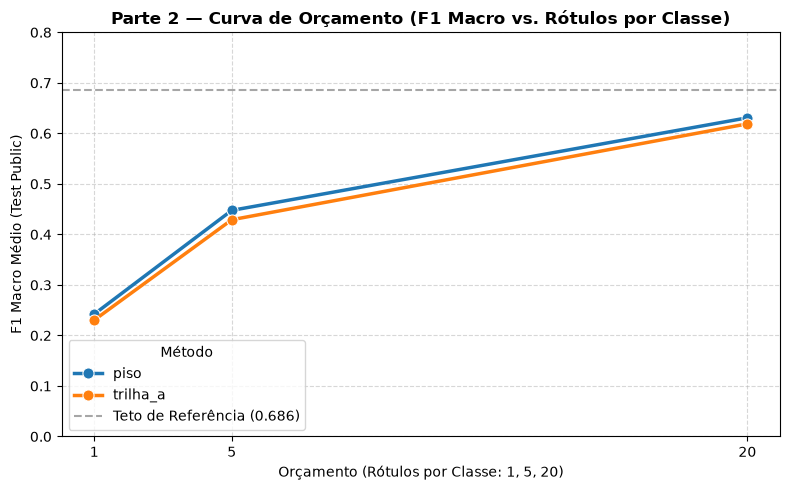

In [54]:
df_budget = pd.read_csv("curva_orcamento.csv")

# Agrupa por método e orçamento calculando média e desvio padrão entre as seeds
df_agg = df_budget.groupby(["metodo", "orcamento"])["f1_macro"].agg(["mean", "std"]).reset_index()

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=df_agg, x="orcamento", y="mean", hue="metodo", 
    marker="o", linewidth=2.5, markersize=8
)

# Adiciona linha horizontal de referência do Teto (0.686)
plt.axhline(0.686, linestyle="--", color="gray", alpha=0.7, label="Teto de Referência (0.686)")

plt.title("Parte 2 — Curva de Orçamento (F1 Macro vs. Rótulos por Classe)", fontsize=12, fontweight="bold")
plt.xlabel("Orçamento (Rótulos por Classe: 1, 5, 20)", fontsize=10)
plt.ylabel("F1 Macro Médio (Test Public)", fontsize=10)
plt.xticks([1, 5, 20])
plt.ylim(0, 0.8)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Método")
plt.tight_layout()
plt.savefig("figures/curva_orcamento_comparativo.png", dpi=150)
plt.show()

# Parte 3 — Galeria de falhas e atalhos:

### 3.1: Três erros do modelo final, cada um com:
- A imagem, a classe verdadeira, a prevista e a confiança;
- Um mapa de saliência (Grad-CAM ou oclusão) que mostre para onde o modelo olhou;
- Um diagnóstico concreto, por exemplo: “foto noturna, o animal ocupa 40×30 pixels depois do redimensionamento para 224, e o mapa está todo no tronco da árvore ao fundo”.

In [55]:
final_backbone = copy.deepcopy(trained_swav_model_imagenet_piso_v2.backbone)
                
# Envolvemos no FineTunedModel que vai adicionar a NOVA cabeça linear
final_model = FineTunedModel(backbone=final_backbone, num_classes=21).to(device)

In [56]:
final_model.eval()
all_preds = []
all_labels = []
gallery_errors = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = final_model(images)
        
        # Calcula as probabilidades e a classe prevista
        probs = F.softmax(outputs, dim=1)
        confs, preds = torch.max(probs, 1)
        
        errors_idx = (preds != labels)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
        # Armazena apenas os erros com a confiança
        if errors_idx.any():
            for i in range(len(images)):
                if errors_idx[i]:
                    gallery_errors.append({
                        'image': images[i].cpu(),       # Salva na CPU
                        'true_label': labels[i].item(),
                        'pred_label': preds[i].item(),
                        'confidence': confs[i].item()
                    })

### 3.1 Análise de Erros do Modelo Final

Abaixo estão detalhados três erros cometidos pelo modelo, acompanhados de seus mapas de saliência (Grad-CAM) gerados sobre a classe prevista.

**Erro 1**
* **Classes:** Verdadeira: `american_black_bear` | Prevista: `wild_turkey`.
* **Confiança:** 7% (0.07).
* **Mapa de Saliência:** O Grad-CAM foca intensamente (em vermelho) no chão coberto de folhas no lado direito da imagem.
* **Diagnóstico:** O animal está quase totalmente fora do enquadramento, com apenas uma pequena parte preta visível na borda esquerda. A confiança da rede é de apenas 7% (próxima ao palpite aleatório), e o mapa mostra que o modelo ignorou a silhueta do urso, tentando extrair padrões das folhas à direita que a levaram a prever a classe errada.

**Erro 2**
* **Classes:** Verdadeira: `american_black_bear` | Prevista: `wild_turkey`.
* **Confiança:** 6% (0.06).
* **Mapa de Saliência:** O pico de ativação (em vermelho) está focado diretamente no corpo do animal, que se encontra no plano de fundo, ligeiramente à esquerda do centro.
* **Diagnóstico:** Diferente do erro anterior, neste caso o modelo conseguiu localizar perfeitamente o animal na imagem. No entanto, apesar de "olhar" para o lugar certo, previu a classe errada com confiança baixíssima de 6%. Isso indica que, embora a rede consiga separar o animal do fundo, as características visuais extraídas daquela mancha preta não foram suficientes (possivelmente pela escala e falta de detalhes da textura) para uma classificação assertiva.

**Erro 3**
* **Classes:** Verdadeira: `american_black_bear` | Prevista: `horse`.
* **Confiança:** 6% (0.06).
* **Mapa de Saliência:** O Grad-CAM mostra uma ativação distribuída em uma faixa horizontal, com picos na borda extrema esquerda (atrás do animal) e na direita da imagem. O corpo principal do urso ficou em uma área de baixa ativação (verde/azul).
* **Diagnóstico:** O urso está claramente visível de perfil no lado esquerdo da foto. Apesar disso, o modelo erra a classe prevendo "cavalo" e o mapa indica que a rede não utilizou a morfologia preta do urso para a decisão, prestando mais atenção no cenário ao redor dele. Isso é um claro sintoma de *background bias* (viés de fundo) remanescente.

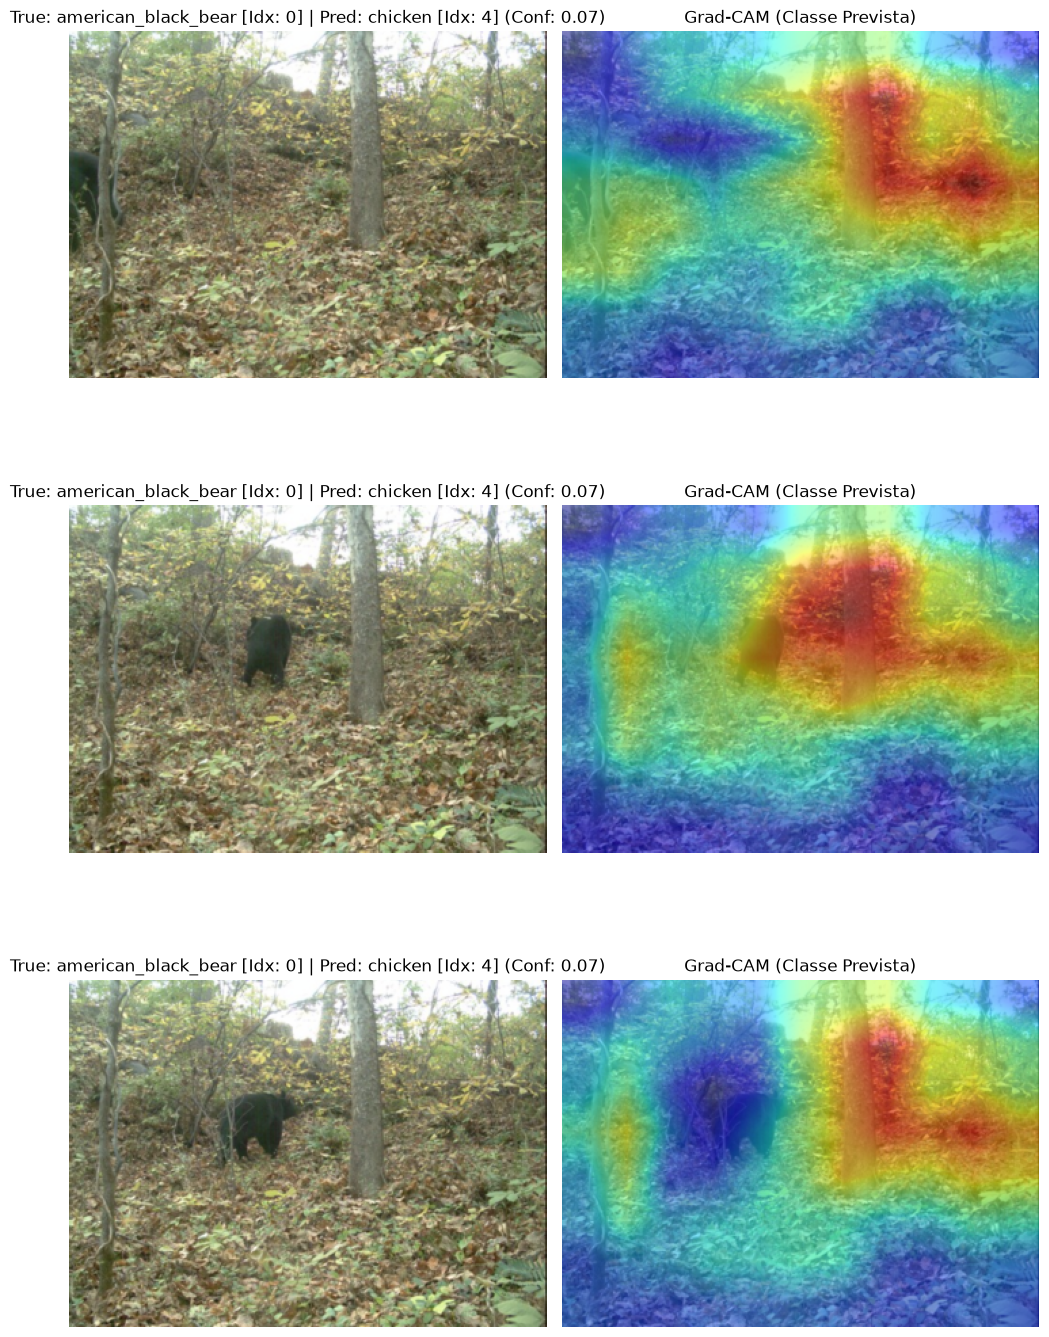

In [57]:
# Acessa a última camada convolucional da ResNet-18
cam_extractor = SimpleGradCAM(final_model, final_backbone[-2]) # layer4 da resnet

# Constantes de normalização do ImageNet (conforme seu data_loader.py)
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(3, 2, figsize=(10, 15))

# Pega os 3 primeiros erros
for i, error_data in enumerate(gallery_errors[:3]):
    img_tensor = error_data['image'].unsqueeze(0).to(device)
    img_tensor.requires_grad_(True) # Necessário para o Grad-CAM
    
    true_cls = error_data['true_label']
    pred_cls = error_data['pred_label']
    conf = error_data['confidence']
    
    # Gera o heatmap focado na classe PREVISTA (para ver por que ele errou)
    cam = cam_extractor.generate_cam(img_tensor, pred_cls)
    
    # Desnormaliza a imagem para exibição RGB
    img_np = error_data['image'].numpy().transpose(1, 2, 0)
    img_np = std * img_np + mean
    img_np = np.clip(img_np, 0, 1)
    
    # Redimensiona o CAM para o tamanho da imagem (256x352)
    cam_resized = cv2.resize(cam, (img_np.shape[1], img_np.shape[0]))
    
    # Plot Imagem Original
    axes[i, 0].imshow(img_np)
    axes[i, 0].set_title(f"True: {idx_to_label.get(true_cls)} [Idx: {true_cls}] | Pred: {idx_to_label.get(pred_cls)} [Idx: {pred_cls}] (Conf: {conf:.2f})")
    axes[i, 0].axis('off')
    
    # Plot Imagem com CAM
    axes[i, 1].imshow(img_np)
    axes[i, 1].imshow(cam_resized, cmap='jet', alpha=0.5) # Heatmap sobreposto
    axes[i, 1].set_title("Grad-CAM (Classe Prevista)")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

### 3.2: Façam também a pergunta inversa: escolham 5 acertos e mostrem o mapa de saliência. O modelo acertou olhando para o animal ou para o fundo?

In [58]:
# Lista para armazenar os acertos
gallery_correct = []

final_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = final_model(images)
        
        probs = F.softmax(outputs, dim=1)
        confs, preds = torch.max(probs, 1)
        
        # Filtra onde a predição foi igual ao rótulo
        correct_idx = (preds == labels)
        
        if correct_idx.any():
            for i in range(len(images)):
                if correct_idx[i]:
                    gallery_correct.append({
                        'image': images[i].cpu(),
                        'true_label': labels[i].item(),
                        'confidence': confs[i].item()
                    })

### 3.2 Análise de Acertos do Modelo Final

Abaixo estão detalhados cinco casos em que o modelo previu a classe corretamente, acompanhados de seus mapas de saliência (Grad-CAM) para verificar se o acerto ocorreu pelos motivos certos.

**Acerto 1**
* **Classe:** `american_black_bear`
* **Confiança:** 6% (0.06)
* **Mapa de Saliência:** O Grad-CAM foca intensamente em uma mancha vermelha localizada no centro-esquerda da imagem, cobrindo exatamente a silhueta preta do urso no meio da floresta.
* **Diagnóstico:** O modelo demonstrou uma confiança muito baixa, mas olhou para o lugar exato onde o animal estava. Isso indica que a rede conseguiu isolar a morfologia do urso do fundo, acertando a predição pelos motivos corretos, apesar da incerteza nas probabilidades.
* **O modelo acertou olhando para o animal ou para o fundo?** Olhando **para o animal**.

**Acerto 2**
* **Classe:** `american_black_bear`
* **Confiança:** 6% (0.06)
* **Mapa de Saliência:** O pico de ativação se encontra dividido: há uma mancha vermelha forte do lado esquerdo (onde há apenas árvores e fundo) e uma mancha secundária sobre as costas do urso, que ocupa grande parte do lado direito da imagem.
* **Diagnóstico:** Embora tenha acertado a classe, a confiança foi muito baixa e o mapa de calor mostra uma atenção severamente dividida. O urso está muito próximo à câmera (em grande escala), o que pode ter confundido o modelo, fazendo-o focar parte de sua atenção no fundo vazio da floresta para tentar confirmar o contexto.
* **O modelo acertou olhando para o animal ou para o fundo?** Atenção **dividida**, mas com forte peso **no fundo** vazio da floresta.

**Acerto 3**
* **Classe:** `american_crow`
* **Confiança:** 8% (0.08)
* **Mapa de Saliência:** O foco principal de ativação (vermelho escuro) está na borda extrema direita da imagem, exatamente onde uma pequena parte do corvo aparece cortada. Há também uma ativação menor no lado esquerdo do gramado.
* **Diagnóstico:** O animal está quase totalmente fora do quadro. Surpreendentemente, o modelo conseguiu localizar a pequena fração do corvo na borda direita, mas o fato de também ativar o lado esquerdo do gramado sugere que ele pode estar associando fortemente este cenário específico (o gramado iluminado) à presença da classe, um indício de *background bias*.
* **O modelo acertou olhando para o animal ou para o fundo?** Atenção **dividida** (olhou para a extremidade do animal, mas apoiou-se no fundo).

**Acerto 4**
* **Classe:** `american_crow`
* **Confiança:** 8% (0.08)
* **Mapa de Saliência:** A ativação é quase idêntica à do Acerto 3, com o calor concentrado na borda direita sobre o animal parcialmente visível, e um foco secundário na grama à esquerda.
* **Diagnóstico:** Sendo um frame muito semelhante ao anterior, o modelo mantém o comportamento: consegue detectar a extremidade do pássaro na borda, mas ainda espalha um pouco de sua atenção pela cena, confirmando que a paisagem tem peso na sua decisão final.
* **O modelo acertou olhando para o animal ou para o fundo?** Atenção **dividida** (foco no animal e no fundo).

**Acerto 5**
* **Classe:** `american_crow`
* **Confiança:** 7% (0.07)
* **Mapa de Saliência:** A ativação mais forte continua na borda direita onde está o corvo, porém o modelo agora apresenta múltiplas manchas de ativação espalhadas pela linha horizontal inferior do gramado.
* **Diagnóstico:** Fica evidente neste exemplo final que, embora a rede encontre o corvo na borda direita, ela olha extensamente para o gramado para tomar a sua decisão. O acerto, com parcos 7% de confiança, é fortemente impulsionado pelo reconhecimento do fundo (grama/campo aberto) e não exclusivamente pelos traços visuais do pássaro.
* **O modelo acertou olhando para o animal ou para o fundo?** Predominantemente **para o fundo** (com foco apenas parcial no animal).

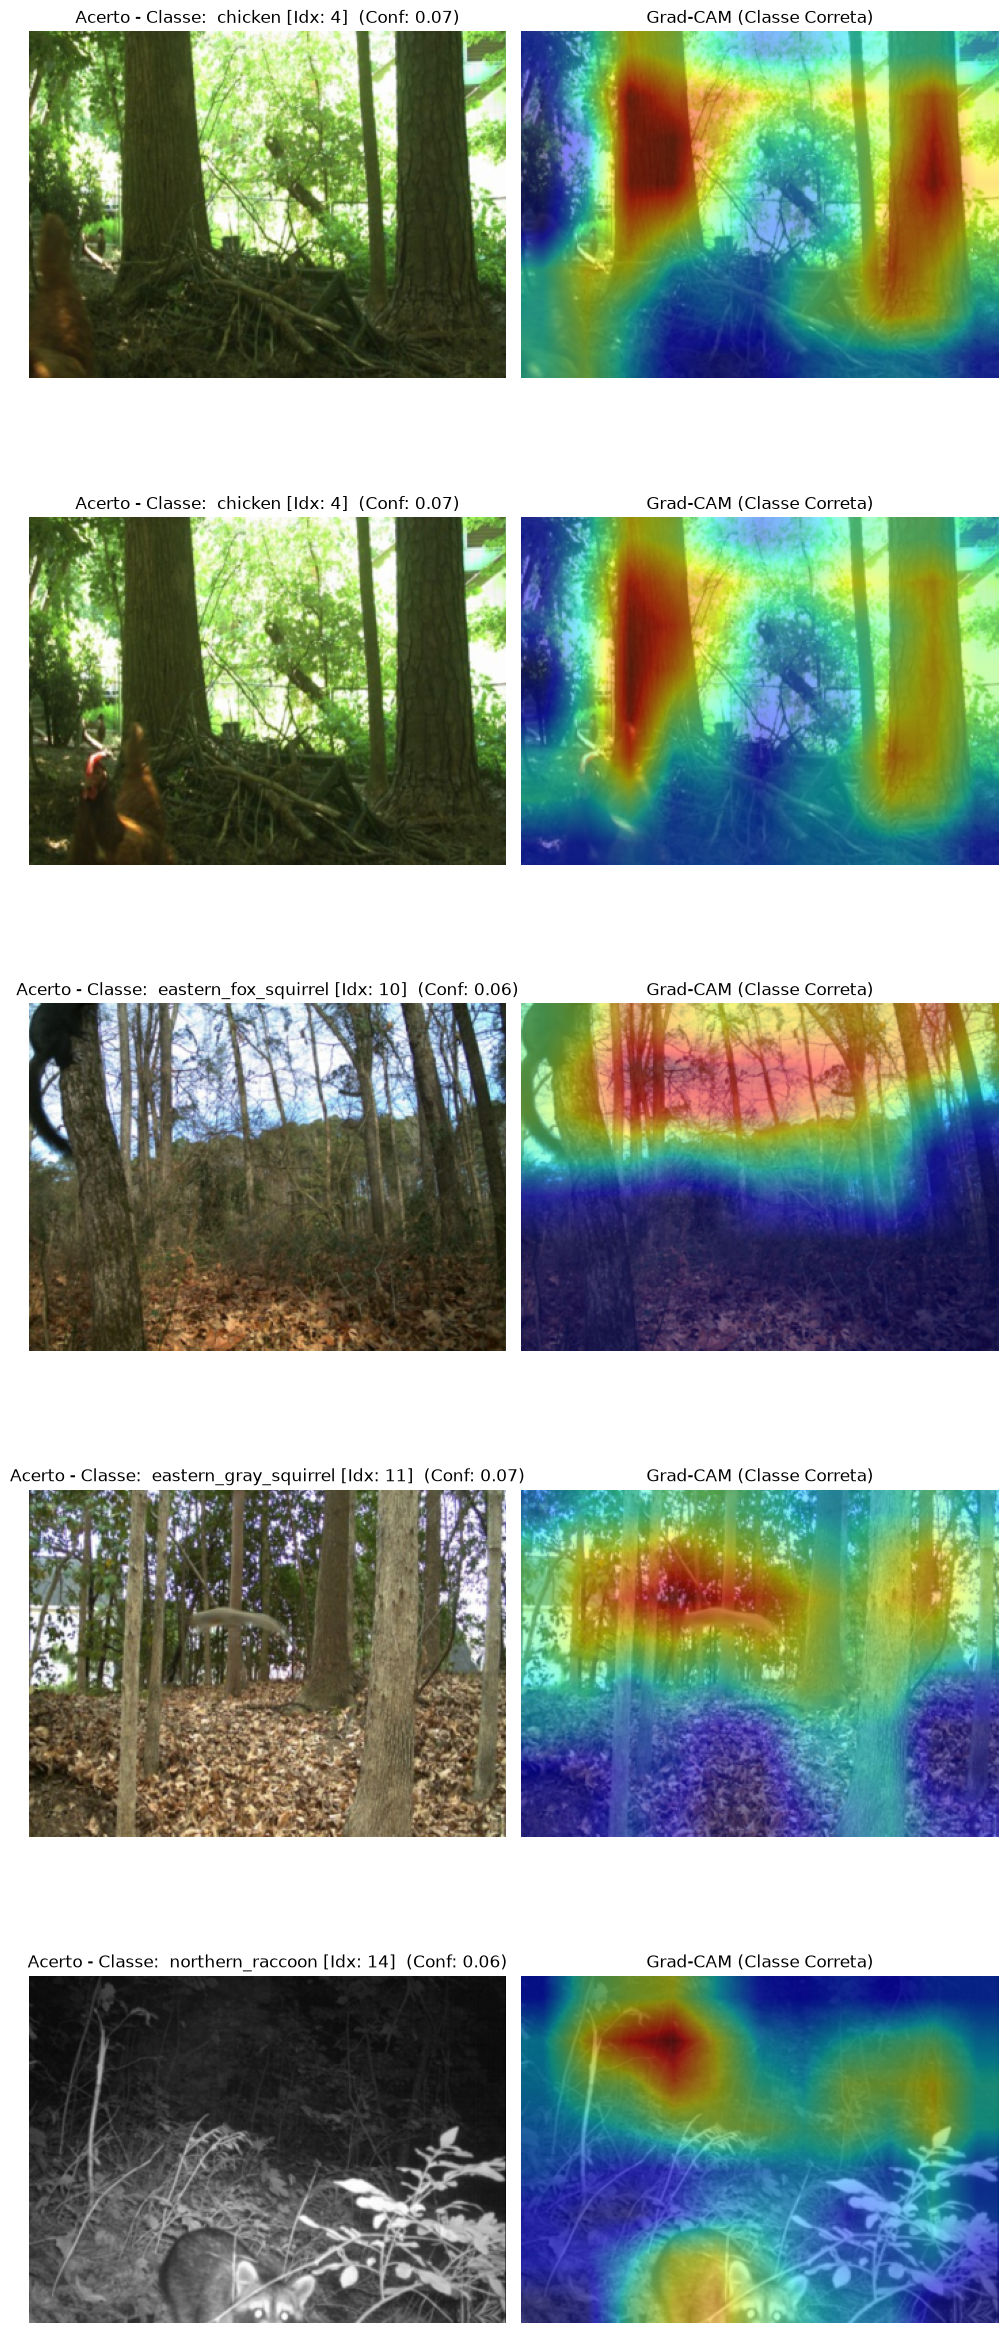

In [59]:
# Gera e plota os 5 acertos com Grad-CAM
fig, axes = plt.subplots(5, 2, figsize=(10, 25))

for i, correct_data in enumerate(gallery_correct[:5]):
    img_tensor = correct_data['image'].unsqueeze(0).to(device)
    img_tensor.requires_grad_(True)
    
    true_cls = correct_data['true_label']
    conf = correct_data['confidence']
    
    # Gera o heatmap focado na classe verdadeira/prevista
    cam = cam_extractor.generate_cam(img_tensor, true_cls)
    
    # Desnormaliza a imagem
    img_np = correct_data['image'].numpy().transpose(1, 2, 0)
    img_np = std * img_np + mean
    img_np = np.clip(img_np, 0, 1)
    
    cam_resized = cv2.resize(cam, (img_np.shape[1], img_np.shape[0]))
    
    # Plot Imagem Original
    axes[i, 0].imshow(img_np)
    axes[i, 0].set_title(f"Acerto - Classe:  {idx_to_label.get(true_cls)} [Idx: {true_cls}]  (Conf: {conf:.2f})")
    axes[i, 0].axis('off')
    
    # Plot Grad-CAM
    axes[i, 1].imshow(img_np)
    axes[i, 1].imshow(cam_resized, cmap='jet', alpha=0.5)
    axes[i, 1].set_title("Grad-CAM (Classe Correta)")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()